# Experiments

The training runs are made by `experiments/run.py` and saved in `results/`, one file per run with its configuration, its learning curves and the evaluation of the final policy. This notebook only reads them. To redo a group of runs:

```bash
uv run python experiments/run.py tuning estimators grid sigma friction
uv run python experiments/variance.py
```

The hyperparameters are chosen on 1000 validation episodes (`VALIDATION_SEED`), so the tuning below shows validation returns. All the other results are on 1000 different test episodes (`TEST_SEED`), so they do not benefit from the choice.

Several experiments contain the central configuration (GPOMDP + baseline, m = 75 kg, C = 0.5, n = 50, lr = 0.01) with the same seeds. A training with the same configuration and seed gives the same policy, so these runs are identical in all of them.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from zamboni.controllers import PDController
from zamboni.training import evaluate

RESULTS = Path("../results")


def load(experiment):
    """All the runs of an experiment, each a dict with its configuration and its arrays."""
    runs = []
    for path in sorted((RESULTS / experiment).glob("*.npz")):
        data = np.load(path)
        config = json.loads(str(data["config"]))
        runs.append(config | {key: data[key] for key in data.files if key != "config"})
    return runs


def mean_and_error(values):
    """Mean and standard error of the mean over the seeds."""
    values = np.asarray(values, dtype=float)
    return values.mean(), values.std(ddof=1) / np.sqrt(len(values))

## Tuning

GPOMDP with its baseline at m = 75 kg and C = 0.5. The batch size n and the initial step size lr of Adam vary, with the same budget of 100 000 training episodes for every run (K = 100 000 / n iterations), and 3 seeds for each pair. The score of a pair is the return of its final policies on the validation episodes, averaged over the seeds.

In [2]:
tuning = load("tuning")
batch_sizes = sorted({run["batch_size"] for run in tuning})
lrs = sorted({run["lr"] for run in tuning})
score = {}
for n in batch_sizes:
    for lr in lrs:
        values = [r["validation_return"] for r in tuning if r["batch_size"] == n and r["lr"] == lr]
        score[n, lr] = mean_and_error(values)

print("validation return in thousands, mean ± standard error over 3 seeds")
print(f"{'n':>4} {'K':>5} " + "".join(f"{f'lr {lr:g}':>15}" for lr in lrs))
for n in batch_sizes:
    cells = "".join(f"{score[n, lr][0] / 1e3:8.1f} ± {score[n, lr][1] / 1e3:4.1f}" for lr in lrs)
    print(f"{n:>4} {100_000 // n:>5} {cells}")
best_n, best_lr = max(score, key=lambda key: score[key][0])
print(f"\nbest: n = {best_n}, lr = {best_lr:g}")

validation return in thousands, mean ± standard error over 3 seeds
   n     K        lr 0.001       lr 0.003        lr 0.01        lr 0.03         lr 0.1
  50  2000   -138.7 ±  3.1   -78.8 ±  3.3   -64.3 ±  0.3   -65.6 ±  0.6   -75.0 ±  3.0
 100  1000   -172.2 ±  0.4  -111.1 ±  2.3   -67.5 ±  0.5   -65.5 ±  0.8  -102.6 ± 29.1
 200   500   -191.3 ±  0.4  -141.3 ±  1.8   -83.1 ±  4.4   -71.3 ±  6.0  -102.3 ±  7.6

best: n = 50, lr = 0.01


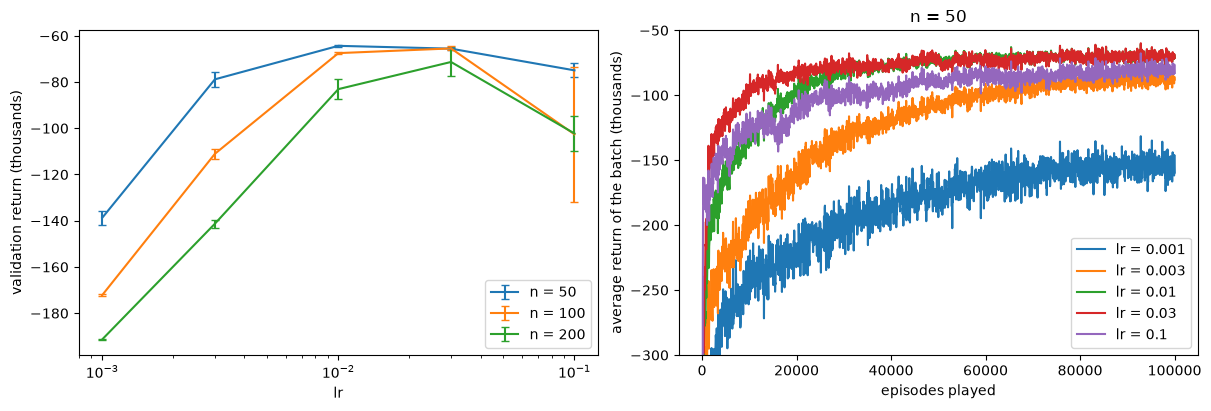

In [3]:
fig, (ax_score, ax_curves) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for n in batch_sizes:
    means = [score[n, lr][0] / 1e3 for lr in lrs]
    errors = [score[n, lr][1] / 1e3 for lr in lrs]
    ax_score.errorbar(lrs, means, yerr=errors, capsize=3, label=f"n = {n}")
ax_score.set_xscale("log")
ax_score.set_xlabel("lr")
ax_score.set_ylabel("validation return (thousands)")
ax_score.legend()

for lr in lrs:  # learning curves at the best n, mean over the seeds
    curves = [r["return"] for r in tuning if r["batch_size"] == best_n and r["lr"] == lr]
    episodes = best_n * np.arange(1, len(curves[0]) + 1)
    ax_curves.plot(episodes, np.mean(curves, axis=0) / 1e3, label=f"lr = {lr:g}")
ax_curves.set_xlabel("episodes played")
ax_curves.set_ylabel("average return of the batch (thousands)")
ax_curves.set_ylim(-300, -50)  # the first iterations fall below
ax_curves.set_title(f"n = {best_n}")
ax_curves.legend()
plt.show()

The chosen pair is n = 50 and lr = 0.01, the defaults of `Config`. The first guess of `training.ipynb` (n = 100, lr = 0.001) is far behind, and lr = 0.001 is the worst value for every n. lr = 0.1 is unstable, its results change a lot from seed to seed. With the same budget a smaller n is better. More updates count more than less noisy gradients.

In the curves on the right, every run starts far below the plot with the initial policy (pure noise). With lr = 0.03 and 0.1 the second iteration falls even lower. The first step of Adam moves every parameter by about lr, and with a large lr that is enough to push the robot far from the rink for one iteration. The next steps bring it back.

## Estimators

The four estimators of `pg1` with the tuned values (n = 50, K = 2000, lr = 0.01), 5 seeds each, at m = 75 kg and C = 0.5. The return is on the test episodes, with the mean action of the final policy. The curves are the batch averages, mean over the seeds.

REINFORCE             test return -102.0 ± 20.1k, targets 1.21
REINFORCE + baseline  test return  -71.5 ±  3.1k, targets 1.90


GPOMDP                test return  -70.7 ±  1.7k, targets 1.95
GPOMDP + baseline     test return  -67.0 ±  0.4k, targets 2.19


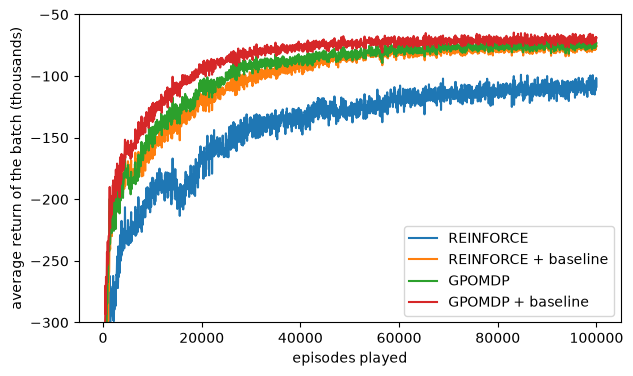

In [4]:
estimators = load("estimators")
names = {
    ("reinforce", False): "REINFORCE",
    ("reinforce", True): "REINFORCE + baseline",
    ("gpomdp", False): "GPOMDP",
    ("gpomdp", True): "GPOMDP + baseline",
}
plt.figure(figsize=(7, 4))
for (estimator, baseline), name in names.items():
    runs = [r for r in estimators if r["estimator"] == estimator and r["baseline"] == baseline]
    mean, error = mean_and_error([r["test_return"] for r in runs])
    targets = np.mean([r["test_targets_reached"] for r in runs])
    print(f"{name:21} test return {mean / 1e3:6.1f} ± {error / 1e3:4.1f}k, targets {targets:.2f}")
    curve = np.mean([r["return"] for r in runs], axis=0)
    plt.plot(50 * np.arange(1, len(curve) + 1), curve / 1e3, label=name)
plt.ylim(-300, -50)
plt.xlabel("episodes played")
plt.ylabel("average return of the batch (thousands)")
plt.legend()
plt.show()

GPOMDP with its baseline is the best and the most stable across seeds. REINFORCE without baseline is the worst and varies a lot from seed to seed. Both techniques of `pg1` help: the baseline and the causality of GPOMDP (each reward weighted only by the scores of the actions before it). The hyperparameters were tuned for GPOMDP + baseline, the main method, which favors it a little. The variance below, measured at fixed parameters, does not depend on the step size and tells the same.

## Variance of the estimators

The variance is measured directly at four points of the GPOMDP + baseline run with seed 0 (`experiments/variance.py`): at each point 4000 trajectories, in batches of 50 as in the training, feed the four estimators. The table gives the variance of each estimator relative to REINFORCE, as a geometric mean over the 17 parameters, whose gradients have very different scales.

In [5]:
variance = json.loads((RESULTS / "variance.json").read_text())
print(f"{'iteration':>9} {'σ (N)':>6}" + "".join(f"{name:>23}" for name in names.values()))
for row in variance:
    cells = "".join(f"{row[name]:>23.3f}" for name in names.values())
    print(f"{row['iteration']:>9} {row['sigma']:>6.1f}{cells}")

iteration  σ (N)              REINFORCE   REINFORCE + baseline                 GPOMDP      GPOMDP + baseline
        0   30.0                  1.000                  0.378                  0.481                  0.221
      100   25.5                  1.000                  0.246                  0.270                  0.082
      500   27.2                  1.000                  0.168                  0.271                  0.054
     1999   22.6                  1.000                  0.195                  0.288                  0.074


At every point GPOMDP + baseline has from 4 to 19 times less variance than REINFORCE: the estimator that learns best in the table above is the one with the least noisy gradient.

## Mass and energy cost

The comparison asked by the assignment: m in {50, 75, 100} kg and C in {0.1, 0.5, 0.9}, inside its ranges, GPOMDP + baseline with the tuned values, 5 seeds per pair. The two PD controllers drive the robot on the same test episodes.

In [6]:
grid = load("grid")
masses = sorted({r["mass"] for r in grid})
costs = sorted({r["energy_coeff"] for r in grid})
print(f"{'m':>4} {'C':>4} {'PG':>15} {'targets':>8} {'LQR PD':>8} {'crit. PD':>9}")
for mass in masses:
    for energy_coeff in costs:
        runs = [r for r in grid if r["mass"] == mass and r["energy_coeff"] == energy_coeff]
        mean, error = mean_and_error([r["test_return"] for r in runs])
        targets = np.mean([r["test_targets_reached"] for r in runs])
        lqr = evaluate(PDController.lqr(mass, energy_coeff).act, mass, energy_coeff)
        pd = evaluate(PDController.critically_damped(mass).act, mass, energy_coeff)
        print(
            f"{mass:>4g} {energy_coeff:>4g} {mean / 1e3:7.1f} ± {error / 1e3:4.1f}"
            f" {targets:>8.2f} {lqr['return'] / 1e3:>8.1f} {pd['return'] / 1e3:>9.1f}"
        )
print("returns in thousands, PG as mean ± standard error over 5 seeds")

   m    C              PG  targets   LQR PD  crit. PD
  50  0.1   -58.1 ±  0.3     2.38    -63.6     -69.1


  50  0.5   -60.8 ±  0.3     2.33    -67.3     -71.5
  50  0.9   -63.2 ±  0.2     2.27    -70.9     -73.9


  75  0.1   -62.0 ±  0.4     2.30    -77.0     -84.2
  75  0.5   -67.0 ±  0.4     2.19    -81.6     -87.2


  75  0.9   -71.6 ±  0.5     2.07    -86.3     -90.1
 100  0.1   -68.3 ±  0.5     2.01    -88.4     -97.1


 100  0.5   -75.3 ±  0.6     1.79    -93.9    -100.5
 100  0.9   -81.6 ±  0.6     1.61    -99.9    -103.9
returns in thousands, PG as mean ± standard error over 5 seeds


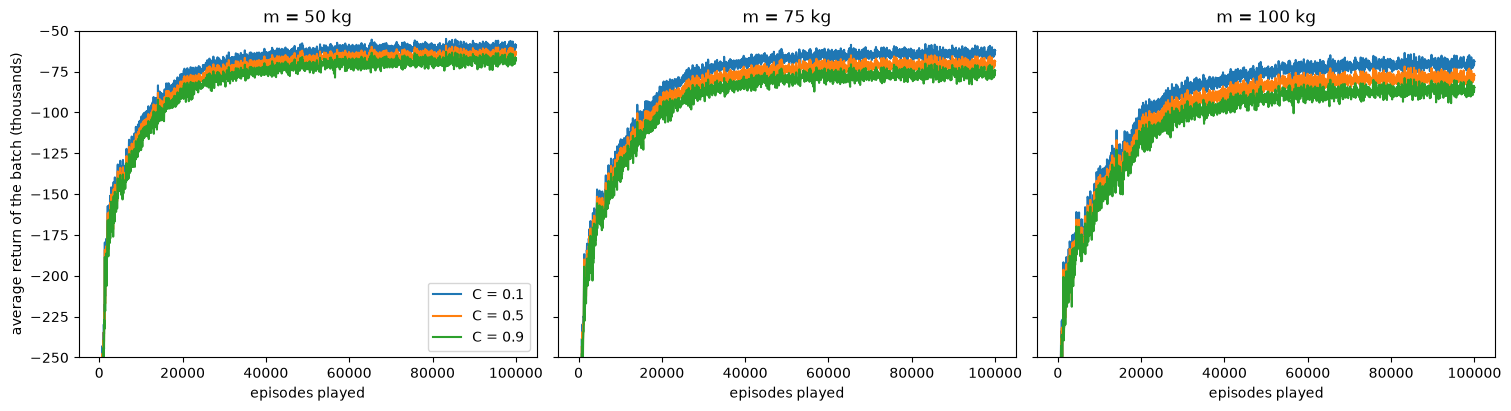

In [7]:
fig, axes = plt.subplots(1, len(masses), figsize=(15, 4), sharey=True, layout="constrained")
for ax, mass in zip(axes, masses, strict=True):
    for energy_coeff in costs:
        runs = [r for r in grid if r["mass"] == mass and r["energy_coeff"] == energy_coeff]
        curve = np.mean([r["return"] for r in runs], axis=0)
        ax.plot(50 * np.arange(1, len(curve) + 1), curve / 1e3, label=f"C = {energy_coeff:g}")
    ax.set_title(f"m = {mass:g} kg")
    ax.set_xlabel("episodes played")
    ax.set_ylim(-250, -50)
axes[0].set_ylabel("average return of the batch (thousands)")
axes[0].legend()
plt.show()

A heavier robot costs more: with the force limited to 100 N it accelerates and brakes more slowly, so it stays farther from the targets. A larger C costs more as well, since the energy weighs more in the cost. The learned policy beats both PD controllers in every configuration, while reaching fewer targets than they do (they reach all three): it does not stop on the target but keeps closer to the center, where the next target is on average nearer (`analysis.ipynb`). The learning curves have the same shape for every pair.

## Learning σ or fixing it

The course treats σ as a hyperparameter, here it is learned. The comparison: σ fixed at 10, 20 and 30 N against σ learned from 30 N, 3 seeds each, tuned values.

In [8]:
sigma_runs = load("sigma")
print(f"{'σ':>16} {'test return':>16} {'targets':>8} {'batch, last 100':>16} {'final σ':>8}")
for sigma0, learned in [(10.0, False), (20.0, False), (30.0, False), (30.0, True)]:
    runs = [r for r in sigma_runs if r["sigma0"] == sigma0 and r["learn_sigma"] == learned]
    mean, error = mean_and_error([r["test_return"] for r in runs])
    targets = np.mean([r["test_targets_reached"] for r in runs])
    batch = np.mean([r["return"][-100:].mean() for r in runs])
    final_sigma = np.mean(
        [np.exp(r["final_theta"][-1]) for r in runs]
    )  # the last parameter is log σ
    label = f"learned from {sigma0:g}" if learned else f"fixed at {sigma0:g}"
    print(
        f"{label:>16} {mean / 1e3:8.1f} ± {error / 1e3:4.1f} {targets:>8.2f}{batch / 1e3:>17.1f}"
        f" {final_sigma:>8.1f}"
    )
print("returns in thousands")

               σ      test return  targets  batch, last 100  final σ
     fixed at 10    -70.6 ±  1.1     1.92            -71.5     10.0
     fixed at 20    -66.6 ±  0.3     2.32            -69.7     20.0
     fixed at 30    -66.2 ±  0.2     2.27            -73.0     30.0
 learned from 30    -66.4 ±  0.3     2.31            -70.2     21.9
returns in thousands


On the test episodes, with the mean action, learning σ does not beat a good fixed value: 20 and 30 N give the same result as the learned σ, while 10 N is worse, because too little noise explores too little. Learning σ removes the choice of its value and lowers the noise at the end of the training (from 30 to about 22 N), which improves the return of the noisy policy: the batch average is better than with σ fixed at 30 N.

## Friction

The second variant of the assignment: `v(t+1) = v(t) + 0.1 (F / m - b v(t))`, with b at the two ends of its range, 0.01 and 0.1. The central configuration (m = 75 kg, C = 0.5, tuned values), 5 seeds for each b. The row b = 0 is GPOMDP + baseline of the estimator comparison. The LQR is computed again with friction, which only changes the velocity row of A: `v(t+1) = (1 - 0.1 b) v(t) + 0.1 F / m`.

In [9]:
friction = load("friction")
without_friction = [r for r in estimators if r["estimator"] == "gpomdp" and r["baseline"]]


def kd_and_pull(theta):
    """kd in N s/m and the pull towards the center in N/m, mean of the two axes (analysis.ipynb)."""
    W = theta[:-1].reshape(2, 8)
    kd = -100 * (W[0, 4] + W[1, 5]) / 2 / 10  # weights of vx/10 and vy/10
    pull = -100 * (W[0, 0] / 30 + W[1, 1] / 15) / 2  # weights of x/30 and y/15
    return kd, pull


print(
    f"{'b':>5} {'PG':>15} {'targets':>8} {'LQR':>7} |"
    f" {'kd':>5} {'kd + m b':>9} {'pull':>5} | {'LQR kd':>7} {'kd + m b':>9}"
)
for b in (0.0, 0.01, 0.1):
    runs = without_friction if b == 0 else [r for r in friction if r["friction"] == b]
    mean, error = mean_and_error([r["test_return"] for r in runs])
    targets = np.mean([r["test_targets_reached"] for r in runs])
    kd, pull = np.mean([kd_and_pull(r["final_theta"]) for r in runs], axis=0)
    lqr = PDController.lqr(75.0, 0.5, b)
    lqr_return = evaluate(lqr.act, 75.0, 0.5, b)["return"]
    print(
        f"{b:>5g} {mean / 1e3:7.1f} ± {error / 1e3:4.1f} {targets:>8.2f} {lqr_return / 1e3:>7.1f} |"
        f" {kd:>5.1f} {kd + 75 * b:>9.1f} {pull:>5.1f} | {lqr.kd:>7.1f} {lqr.kd + 75 * b:>9.1f}"
    )
print("returns in thousands, PG as mean ± standard error over 5 seeds, gains of the mean action")

    b              PG  targets     LQR |    kd  kd + m b  pull |  LQR kd  kd + m b
    0   -67.0 ±  0.4     2.19   -81.6 |   8.2       8.2   1.9 |    46.0      46.0
 0.01   -67.0 ±  0.3     2.22   -81.9 |   8.0       8.7   1.9 |    45.3      46.1
  0.1   -69.2 ±  0.4     2.28   -86.0 |   3.0      10.5   1.8 |    39.2      46.7
returns in thousands, PG as mean ± standard error over 5 seeds, gains of the mean action


The learned policy beats the LQR with both values of b: −67.0 against −81.9 thousand with b = 0.01, −69.2 against −86.0 with b = 0.1. With b = 0.01 almost nothing changes.

With b = 0.1 the learned kd drops from 8.2 to 3.0 N s/m. Friction also brakes, with a force m b v, so without saturation the braking proportional to the velocity is kd + m b. For the learned policy it goes from 8.2 to 10.5. The LQR lowers its kd as well and keeps kd + m b near 46. The pull towards the center stays about the same in the cases examined, 1.8 to 1.9 N/m.